# HW04 降维、PCA 与 UMAP

- 姓名：温良玉
- 学号：32620222200441
- 日期：2026-11-05
- 输入：`assignments/hw04/resources/data/leukemia/leukemia.csv`，72 行 × 7132 列，去掉 `sample_id`、`original_split`、`diagnosis` 后为 72 × 7129
- 拟合范围：任务 1 的可选验证只在原始 38 个训练样本内做 3 折；任务 2、任务 3 只描述全部 72 行，拟合范围是全部 72 行，不涉及任何预测评价
- 运行缓存、坐标表与可重生成的图片统一保存到项目根目录 `.tmp/dimension-reduction/student-results/`

## 〇、初始判断（先写再看结果）

- 判断：**不同意**“二维图分得开 = 发现了疾病机制，并且可以预测新患者”。
- 信心（0–100）：**80**
- 最想补充的证据：**同一批样本在两个独立批次上重复降维，看分组是否重现；以及在一批从未参与分析的新患者上的预测表现。**


In [1]:
%matplotlib inline
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score

HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents]
             if (p / "assignments/hw04/resources/data/leukemia/leukemia.csv").exists()), None)
if ROOT is None:
    raise RuntimeError("请在课程仓库内运行 HW04 Notebook：找不到 assignments/hw04/resources/data/leukemia/leukemia.csv")

OUT = ROOT / ".tmp/dimension-reduction/student-results"
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
COLORS = {"ALL": "#387ca3", "AML": "#d57839"}

print("项目根目录:", ROOT)
print("输出目录  :", OUT)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
try:
    import umap
    print("umap-learn", umap.__version__)
except ImportError:
    raise RuntimeError("缺少 umap-learn，请先 pip install -r assignments/hw04/resources/requirements.txt")


项目根目录: /Users/wenliangyu/Desktop/人工智能课程ppt资料作业/git-practice-classroom
输出目录  : /Users/wenliangyu/Desktop/人工智能课程ppt资料作业/git-practice-classroom/.tmp/dimension-reduction/student-results
Python 3.12.9 | numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.8.0 | matplotlib 3.10.8


umap-learn 0.5.12


In [2]:
df = pd.read_csv(ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv")
META = ["sample_id", "original_split", "diagnosis"]
X = df.drop(columns=META)
y = df["diagnosis"].to_numpy()
Xv = X.to_numpy(dtype=float)

assert X.shape == (72, 7129), X.shape
assert np.isfinite(Xv).all()
assert set(np.unique(y)) == {"ALL", "AML"}

print("一行 = 一份患者样本；一列 = 一个探针")
print("矩阵形状:", X.shape)
print("类别计数:", df["diagnosis"].value_counts().to_dict())
print("原始划分:", df["original_split"].value_counts().to_dict())
print("探针名重复（同一名字可对应多个探针）:", int(X.columns.duplicated().sum()))
print("列最小值 / 最大值:", Xv.min(), "/", Xv.max())


一行 = 一份患者样本；一列 = 一个探针
矩阵形状: (72, 7129)
类别计数: {'ALL': 47, 'AML': 25}
原始划分: {'train': 38, 'test': 34}
探针名重复（同一名字可对应多个探针）: 0
列最小值 / 最大值: -28400.0 / 71369.0


## 任务 1：降维是为了看图，还是预测新样本？

### 1.1 目标—输出—评价表

| 目的 | 需要什么输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 二维或三维坐标；每个轴上标注该轴解释率（PCA）或明确说明无解释率（UMAP）；坐标与 `sample_id` 的对应表 | 换参数或种子后结构是否重现；能不能指出某个点是哪个样本；不把轴或簇的位置当成生物学量 |
| 去噪 | 保留前若干主成分的重建矩阵，或用低方差 / 低稳定方向被削弱的表示 | 需要重复测量或下游实验验证；“图看起来更整齐”不是证据，标准化的代价是可能放大低变异噪声 |
| 压缩特征 | 较少的坐标、重建误差、累计解释率、以及对新样本可施加的同一变换 | 在同一个下游任务上，用更少维数得到不劣的表现，同时计算与存储成本下降 |
| 发现样本结构 | 邻域关系、候选分组、梯度、离群点 | 邻域和分组在参数、种子、独立批次下是否重现；需要外部信息（临床、遗传学、批次）来确认，单凭图不行 |
| 作为后续模型输入 | 训练阶段拟合好的标准化 + PCA，可对新样本 `transform` 的特征 | 全流程放进 Pipeline、折内拟合的交叉验证，以及固定方案后只用一次独立测试集 |


### 1.2 两条流程（标出拟合范围）

**流程 A：描述这 72 个样本（允许全数据拟合）**

```
表达矩阵 72×7129
   │  ← 拟合范围：全部 72 行
StandardScaler().fit_transform  →  Z（列均值 0、总体标准差 1）
   │  ← 拟合范围：全部 72 行
PCA(svd_solver='full') / UMAP(...)  →  二维坐标
   │  ← 标签不参与任何一步拟合
用 diagnosis 事后着色
```

产出只能描述“这 72 个样本在这套参数下长什么样”，不能用于评价预测能力。

**流程 B：评估新样本预测（必须折内拟合）**

```
先划分 train / test（此处沿用 original_split 38 / 34）
   │
对每个训练折：
   ├─ StandardScaler().fit(训练折) → transform(训练折) / transform(验证折)
   ├─ PCA(...).fit(训练折标准化后)  → transform(训练折) / transform(验证折)
   └─ 分类器.fit(训练折的降维结果)
   │
预测验证折 → 汇总交叉验证指标
   │
固定方案后，只在测试集上评估一次
```

拟合范围只有训练折。验证折参与计算的只有 `transform`，不参与任何 `fit`。

### 1.3 为什么“PCA 没用标签，所以可以全数据先 PCA 再交叉验证”仍然泄露

PCA 的每一列均值 μ、标准差 s 和协方差矩阵，都是从喂进去的**所有样本**算出来的。在全 72 行上 `fit` 之后再交叉验证，验证折的观测已经进入过 μ、s 和主成分方向的估计，主成分因此朝着“包含验证折”的方向倾斜；验证折不再是没见过的数据，分数偏乐观。**标签没有被使用，不代表样本信息没有被使用。** 正确做法是把 `StandardScaler` 和 `PCA` 都放进 `Pipeline`，让它们在每折内单独 `fit`。


In [3]:
# 任务 1 可选验证：只在原始 38 个训练样本内做，不读取测试标签、不用测试集调参
train_mask = df["original_split"].eq("train").to_numpy()
Xtr, ytr = Xv[train_mask], y[train_mask]
print("训练样本:", Xtr.shape, "| ALL/AML:", pd.Series(ytr).value_counts().to_dict())

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
rows = []
for fold, (itr, iva) in enumerate(skf.split(Xtr, ytr), start=1):
    variants = {
        "StandardScaler → 1NN": [StandardScaler(), KNeighborsClassifier(n_neighbors=1)],
        "StandardScaler → PCA(10) → 1NN": [StandardScaler(),
                                           PCA(n_components=10, svd_solver="full"),
                                           KNeighborsClassifier(n_neighbors=1)],
    }
    for name, steps in variants.items():
        pipe = make_pipeline(*steps).fit(Xtr[itr], ytr[itr])   # 全部 fit 都在训练折内
        rows.append({"fold": fold, "pipeline": name,
                     "n_train": len(itr), "n_val": len(iva),
                     "train_ba": balanced_accuracy_score(ytr[itr], pipe.predict(Xtr[itr])),
                     "val_ba": balanced_accuracy_score(ytr[iva], pipe.predict(Xtr[iva]))})

cv = pd.DataFrame(rows)
print("\n各折 balanced accuracy（平衡准确率 = 两类召回率的平均）")
print(cv.pivot(index="fold", columns="pipeline", values="val_ba").round(4).to_string())
print("\n汇总")
print(cv.groupby("pipeline")["val_ba"].agg(["mean", "min", "max"]).round(4).to_string())
print("\n注意：训练折 BA 恒为 1.0，因为 1 近邻在训练集上总是先找到自己（距离 0），这个数字不含模型优劣信息。")
cv.to_csv(OUT / "task1-training-only-cv.csv", index=False)


训练样本: (38, 7129) | ALL/AML: {'ALL': 27, 'AML': 11}

各折 balanced accuracy（平衡准确率 = 两类召回率的平均）
pipeline  StandardScaler → 1NN  StandardScaler → PCA(10) → 1NN
fold                                                          
1                       0.8194                          0.6944
2                       0.8750                          0.7639
3                       0.8333                          0.8333

汇总
                                  mean     min     max
pipeline                                              
StandardScaler → 1NN            0.8426  0.8194  0.8750
StandardScaler → PCA(10) → 1NN  0.7639  0.6944  0.8333

注意：训练折 BA 恒为 1.0，因为 1 近邻在训练集上总是先找到自己（距离 0），这个数字不含模型优劣信息。


**任务 1 的观察**

- 3 折验证 BA：`StandardScaler → 1NN` 为 0.8194 / 0.8750 / 0.8333（均值 0.8426），`StandardScaler → PCA(10) → 1NN` 为 0.6944 / 0.7639 / 0.8333（均值 0.7639）。
- 逐折比较：全探针胜 2 折、平 1 折、PCA(10) 胜 0 折。**但只有 3 折、n=38，样本量太小，不能据此给两种方案排名**，只能说这次没有观察到 PCA(10) 更好。
- 训练折 BA 全部 1.0000，不构成任何证据（1 近邻在训练集上以自己的距离 0 为最近邻）。
- 这一小节的分数可以乐观到什么程度：这里只是**选方案**用的内部验证，真正的测试集不能再用来看结果，否则就退回到数据泄露。


In [4]:
# 任务 2.1 标准化
scaler = StandardScaler()
Z = scaler.fit_transform(Xv)

print("列均值最大绝对偏差      :", f"{np.abs(Z.mean(axis=0)).max():.3e}")
print("列总体标准差与 1 的最大偏差 (ddof=0):", f"{np.abs(Z.std(axis=0, ddof=0) - 1).max():.3e}")
print("整体均值 / 整体标准差    :", f"{Z.mean():.3e}", "/", f"{Z.std(ddof=0):.6f}")
print("常量列个数              :", int((Xv.std(axis=0) == 0).sum()))
print("\n对照——标准化前各列方差：最小 %.3e  中位数 %.3e  最大 %.3e  （最大/最小 = %.0f 倍）"
      % (Xv.var(axis=0).min(), np.median(Xv.var(axis=0)), Xv.var(axis=0).max(),
         Xv.var(axis=0).max() / Xv.var(axis=0).min()))
print("本数据含负值，不是 RNA-seq 原始计数，因此不取 log/log1p；")
print("标准化也不等于微阵列上游归一化和批次处理，它只把每列换成自身标准差为单位。")


列均值最大绝对偏差      : 5.983e-16
列总体标准差与 1 的最大偏差 (ddof=0): 3.331e-16
整体均值 / 整体标准差    : -6.212e-19 / 1.000000
常量列个数              : 0

对照——标准化前各列方差：最小 7.032e+02  中位数 3.386e+04  最大 2.491e+08  （最大/最小 = 354257 倍）
本数据含负值，不是 RNA-seq 原始计数，因此不取 log/log1p；
标准化也不等于微阵列上游归一化和批次处理，它只把每列换成自身标准差为单位。


In [5]:
# 任务 2.2 标准化矩阵上的 PCA（27,000 次不用，svd_solver='full' 精确分解）
pca = PCA(svd_solver="full").fit(Z)
S = pca.transform(Z)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

print("PC1 explained variance ratio = %.6f  (%.3f%%)" % (evr[0], evr[0] * 100))
print("PC2 explained variance ratio = %.6f  (%.3f%%)" % (evr[1], evr[1] * 100))
print("PC1 + PC2                    = %.6f  (%.3f%%)" % (evr[:2].sum(), evr[:2].sum() * 100))
print("PC1 方差 = %.4f   PC2 方差 = %.4f   总方差（迹）= %.1f"
      % (pca.explained_variance_[0], pca.explained_variance_[1], pca.explained_variance_.sum()))
print("\n累计解释率：")
for k in [2, 3, 5, 10, 20, 50, 71]:
    print("  前 %2d 个主成分: %.6f (%.2f%%)" % (k, cum[k - 1], cum[k - 1] * 100))
print("\n返回的主成分个数:", len(evr),
      "| 矩阵秩:", np.linalg.matrix_rank(Z),
      "| 第 72 个主成分方差: %.3e（数值零）" % pca.explained_variance_[-1])


PC1 explained variance ratio = 0.149216  (14.922%)
PC2 explained variance ratio = 0.094462  (9.446%)
PC1 + PC2                    = 0.243678  (24.368%)
PC1 方差 = 1078.7424   PC2 方差 = 682.9024   总方差（迹）= 7229.4

累计解释率：
  前  2 个主成分: 0.243678 (24.37%)
  前  3 个主成分: 0.290380 (29.04%)
  前  5 个主成分: 0.365014 (36.50%)
  前 10 个主成分: 0.491773 (49.18%)
  前 20 个主成分: 0.641342 (64.13%)
  前 50 个主成分: 0.897234 (89.72%)
  前 71 个主成分: 1.000000 (100.00%)

返回的主成分个数: 72 | 矩阵秩: 71 | 第 72 个主成分方差: 2.127e-28（数值零）


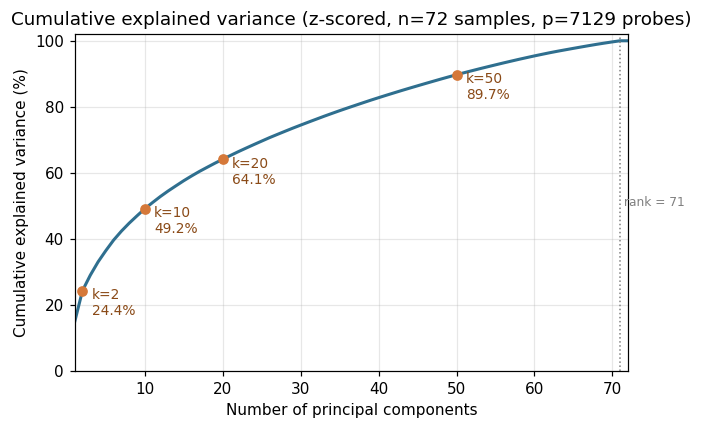

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(np.arange(1, len(cum) + 1), cum * 100, color="#2f6f8f", lw=2)
ax.scatter([2, 10, 20, 50], [cum[1] * 100, cum[9] * 100, cum[19] * 100, cum[49] * 100],
           color="#d57839", zorder=3)
for k in [2, 10, 20, 50]:
    ax.annotate(f"k={k}\n{cum[k-1]*100:.1f}%", xy=(k, cum[k - 1] * 100),
                xytext=(6, -16), textcoords="offset points", fontsize=9, color="#8a4a17")
ax.axvline(71, ls=":", color="grey", lw=1)
ax.text(71, 50, " rank = 71", fontsize=8, color="grey")
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance (%)",
       title="Cumulative explained variance (z-scored, n=72 samples, p=7129 probes)",
       xlim=(1, 72), ylim=(0, 102))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "fig-pca-cumulative.png", bbox_inches="tight")
plt.show()


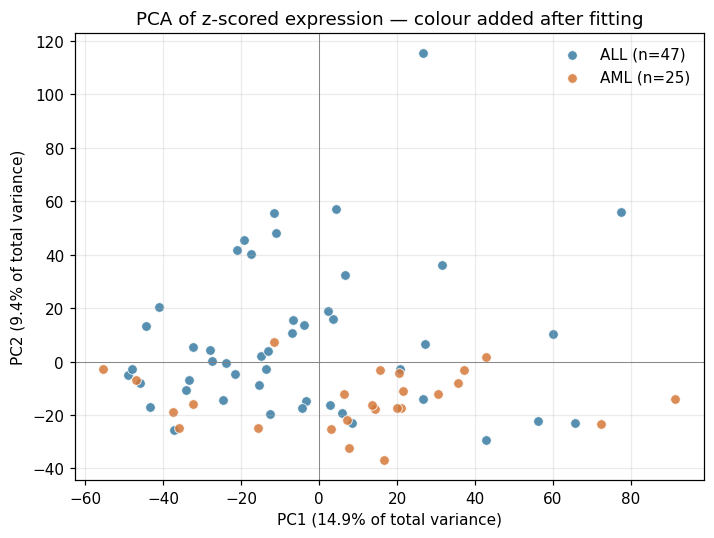

PC1 得分范围: -55.340 ~ 91.383
PC1 与 AML 指示变量的点二列相关: r = 0.2164


In [7]:
# 任务 2.2 散点图：先拟合，后按诊断着色（标签不参与 PCA）
fig, ax = plt.subplots(figsize=(6.6, 5.0))
for label in ["ALL", "AML"]:
    m = y == label
    ax.scatter(S[m, 0], S[m, 1], s=40, alpha=0.85, c=COLORS[label],
               edgecolor="white", linewidth=0.6, label=f"{label} (n={m.sum()})")
ax.set(xlabel=f"PC1 ({evr[0]:.1%} of total variance)",
       ylabel=f"PC2 ({evr[1]:.1%} of total variance)",
       title="PCA of z-scored expression — colour added after fitting")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
plt.tight_layout()
plt.savefig(OUT / "fig-pca-pc1-pc2.png", bbox_inches="tight")
plt.show()

is_aml = (y == "AML").astype(int)
print("PC1 得分范围: %.3f ~ %.3f" % (S[:, 0].min(), S[:, 0].max()))
print("PC1 与 AML 指示变量的点二列相关: r = %.4f" % np.corrcoef(S[:, 0], is_aml)[0, 1])


In [8]:
# 任务 2.3 PC1 中绝对权重最大的 5 个探针（loading = components_.T，即方向权重）
w1 = pd.Series(pca.components_[0], index=X.columns)
top5 = w1.reindex(w1.abs().nlargest(5).index)
table = pd.DataFrame({"probe": top5.index,
                      "PC1 loading (signed)": top5.to_numpy(),
                      "|loading|": top5.abs().to_numpy()}).set_index("probe")
print("PC1 方向权重绝对值前 5 的探针")
print(table.to_string(float_format=lambda v: f"{v:+.6f}"))
print("\n全部 7129 个探针在 PC1 上权重的绝对值：中位数 %.6f，最大 %.6f"
      % (w1.abs().median(), w1.abs().max()))
table.to_csv(OUT / "task2-pc1-top5-loadings.csv")

# 手工核对：样本 i 的 PC1 得分 = Σ_j w_j * z_ij
i = 0
manual = float(Z[i] @ w1.to_numpy())
print("\n手工核对样本 %s：Σ w_j·z_ij = %.6f，sklearn 给出 %.6f，差 %.1e"
      % (df.sample_id[i], manual, S[i, 0], abs(manual - S[i, 0])))
approx = float(Z[i, np.argsort(-w1.abs().to_numpy())[:5]] @ top5.to_numpy())
print("只用这 5 个探针近似同一得分：%.4f（真值的 %.1f%%）→ 单个权重再大也只是和里的一项"
      % (approx, 100 * approx / S[i, 0]))


PC1 方向权重绝对值前 5 的探针
             PC1 loading (signed)  |loading|
probe                                       
X92518_s_at             +0.028786  +0.028786
X95190_at               -0.028177  +0.028177
X98253_at               +0.027927  +0.027927
X82895_at               +0.027871  +0.027871
Y09616_at               +0.027757  +0.027757

全部 7129 个探针在 PC1 上权重的绝对值：中位数 0.008561，最大 0.028786

手工核对样本 G001：Σ w_j·z_ij = 27.105207，sklearn 给出 27.105207，差 3.9e-14
只用这 5 个探针近似同一得分：0.1351（真值的 0.5%）→ 单个权重再大也只是和里的一项


In [9]:
# 反驳“PC1 就是最能区分 ALL/AML 的方向”：用数据本身检验
def best_threshold_ba(score, labels):
    best = (-1.0, None)
    for t in np.sort(score)[:-1]:
        best = max(best, (balanced_accuracy_score(labels, np.where(score > t, "AML", "ALL")), t))
    return best

# 类别均值差方向（需要标签，只作对照，不参与 PCA）
mean_dir = Z[is_aml == 1].mean(axis=0) - Z[is_aml == 0].mean(axis=0)
mean_dir /= np.linalg.norm(mean_dir)

ba_pc1 = best_threshold_ba(S[:, 0], y)
ba_mean = best_threshold_ba(Z @ mean_dir, y)
cos = abs(float(np.dot(pca.components_[0], mean_dir)))

print("沿 PC1 单阈值分类的最优 BA        : %.4f" % ba_pc1[0])
print("沿类别均值差方向单阈值分类的最优 BA: %.4f" % ba_mean[0])
print("PC1 方向与类别均值差方向的 |cos|   : %.4f" % cos)
print("PC1 承载了该判别方向能量的比例     : %.4f" % (cos ** 2))
print("=> PC1 是“方差最大”的方向，不是“最能区分疾病”的方向。")


沿 PC1 单阈值分类的最优 BA        : 0.7123
沿类别均值差方向单阈值分类的最优 BA: 0.9281
PC1 方向与类别均值差方向的 |cos|   : 0.3841
PC1 承载了该判别方向能量的比例     : 0.1475
=> PC1 是“方差最大”的方向，不是“最能区分疾病”的方向。


原尺度 PC1 0.174278 (17.428%)  PC2 0.103386 (10.339%)  合计 27.766%
标准化 PC1 0.149216 (14.922%)  PC2 0.094462 (9.446%)  合计 24.368%

原尺度 PC1 权重绝对值前 5：
                     loading
M25079_s_at        +0.352388
hum_alu_at         +0.313552
HG1428-HT1428_s_at +0.234867
L06499_at          +0.210453
J04617_s_at        +0.196253

两种口径 top5 探针交集: 空集
原尺度各列方差最大/最小 = 354257 倍，方差最大的列主导了原尺度 PC1 的方向。

判别力对照（最优单阈值 BA，事后描述，不是预测性能）：
  原尺度   PC1 0.5749   PC2 0.9494
  标准化   PC1 0.7123   PC2 0.4894


  原尺度前两维 留一 1NN BA: 0.9081


  标准化前两维 留一 1NN BA: 0.6430


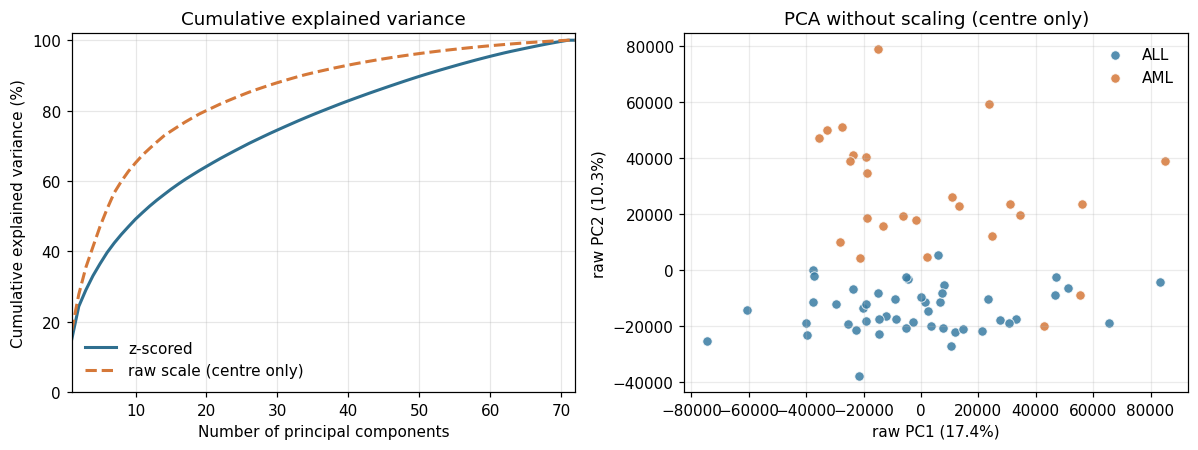

In [10]:
# 任务 2.4 原尺度 PCA：只中心化、不标准化
pca_raw = PCA(svd_solver="full").fit(Xv)      # PCA 总是先中心化，这里不除以标准差
S_raw = pca_raw.transform(Xv)
evr_raw = pca_raw.explained_variance_ratio_
cum_raw = np.cumsum(evr_raw)
w1_raw = pd.Series(pca_raw.components_[0], index=X.columns)
top5_raw = w1_raw.reindex(w1_raw.abs().nlargest(5).index)

print("原尺度 PC1 %.6f (%.3f%%)  PC2 %.6f (%.3f%%)  合计 %.3f%%"
      % (evr_raw[0], evr_raw[0] * 100, evr_raw[1], evr_raw[1] * 100, evr_raw[:2].sum() * 100))
print("标准化 PC1 %.6f (%.3f%%)  PC2 %.6f (%.3f%%)  合计 %.3f%%"
      % (evr[0], evr[0] * 100, evr[1], evr[1] * 100, evr[:2].sum() * 100))
print("\n原尺度 PC1 权重绝对值前 5：")
print(top5_raw.to_frame("loading").to_string(float_format=lambda v: f"{v:+.6f}"))
print("\n两种口径 top5 探针交集:", set(top5.index) & set(top5_raw.index) or "空集")
print("原尺度各列方差最大/最小 = %.0f 倍，方差最大的列主导了原尺度 PC1 的方向。"
      % (Xv.var(axis=0).max() / Xv.var(axis=0).min()))
top5_raw.to_frame("loading").to_csv(OUT / "task2-pc1-top5-loadings-raw-scale.csv")

# 判别力对照（描述性；阈值在全部 72 行上事后挑选，不构成模型评价）
def best_threshold_ba(score, labels):
    best = (-1.0, None)
    for t in np.sort(score)[:-1]:
        best = max(best, (balanced_accuracy_score(labels, np.where(score > t, "AML", "ALL")), t))
    return best

print()
print("判别力对照（最优单阈值 BA，事后描述，不是预测性能）：")
print("  原尺度   PC1 %.4f   PC2 %.4f" % (best_threshold_ba(S_raw[:, 0], y)[0],
                                          best_threshold_ba(S_raw[:, 1], y)[0]))
print("  标准化   PC1 %.4f   PC2 %.4f" % (best_threshold_ba(S[:, 0], y)[0],
                                          best_threshold_ba(S[:, 1], y)[0]))
for tag, M in [("原尺度前两维", S_raw[:, :2]), ("标准化前两维", S[:, :2])]:
    pred = NearestNeighbors(n_neighbors=2).fit(M).kneighbors(M, return_distance=False)[:, 1]
    print("  %s 留一 1NN BA: %.4f" % (tag, balanced_accuracy_score(y, y[pred])))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(np.arange(1, len(cum) + 1), cum * 100, color="#2f6f8f", lw=2, label="z-scored")
axes[0].plot(np.arange(1, len(cum_raw) + 1), cum_raw * 100, color="#d57839", lw=2, ls="--", label="raw scale (centre only)")
axes[0].set(xlabel="Number of principal components", ylabel="Cumulative explained variance (%)",
            title="Cumulative explained variance", xlim=(1, 72), ylim=(0, 102))
axes[0].legend(frameon=False); axes[0].grid(alpha=0.3)

for label in ["ALL", "AML"]:
    m = y == label
    axes[1].scatter(S_raw[m, 0], S_raw[m, 1], s=38, alpha=0.85, c=COLORS[label],
                    edgecolor="white", linewidth=0.6, label=label)
axes[1].set(xlabel=f"raw PC1 ({evr_raw[0]:.1%})", ylabel=f"raw PC2 ({evr_raw[1]:.1%})",
            title="PCA without scaling (centre only)")
axes[1].legend(frameon=False); axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "fig-pca-raw-vs-scaled.png", bbox_inches="tight")
plt.show()


### 任务 2.5 原尺度对照说明了什么

**意外的地方（如实报告）。** 原尺度 PC2 的单阈值最优 BA 是 **0.9494**，远高于标准化 PC2 的 **0.4894**；原尺度前两维的留一 1NN BA 为 **0.9081**，标准化后只有 **0.6430**。也就是说，在这份数据里方差最大的那些列同时也带着 ALL/AML 的判别信息，标准化把它们压到和其余列同样权重，反而稀释了信号。

**但这不能反推“原尺度更好”。** 三点限制：(a) 阈值是在全部 72 行上、看过标签之后挑的，属于事后描述，不是模型评价；(b) 原尺度 PC 的方向由少数几列主导，本次前五是 `M25079_s_at`(+0.352)、`hum_alu_at`(+0.314)、`HG1428-HT1428_s_at`(+0.235)、`L06499_at`(+0.210)、`J04617_s_at`(+0.196)，其中 `hum_alu_at` 是 Alu 重复序列探针，这类高丰度/管家类信号也可能携带 RNA 投入量、杂交效率等技术差异，无法在本数据里与疾病信号分开；(c) 要判断哪种口径更好，必须在训练折内拟合、在独立样本上比较，不能用同一批样本的事后 BA 排名。

**标准化的作用与代价。** 作用是让 7129 列在同一把尺子上加权，主成分反映的是**相关结构**而不是量纲——不标准化时各列方差相差约 35 万倍，PC1 几乎被大方差列独占。代价是把低变异列（可能主要是测量噪声）的相对权重放大到与真实信号列相同，也可能像本例这样，削弱了“大方差列里顺带的判别信号”。因此本报告两种口径都保留并写明差异，而不是只报解释率更高的那个。

### 任务 2 的问题回答

**PC1 最大化的是什么方差？** 在单位长度约束下，使投影 `t₁ = Z w₁` 的方差最大的那个方向的方差。实测 PC1 方差 1078.74，解释总方差（迹 7229.4）的 14.92%。它与“最能区分 ALL/AML 的方向”不是一回事：沿 PC1 单阈值分类的最优 BA 只有 0.7123，而沿类别均值差方向可达 0.9281，两个方向的 |cos| 只有 0.3841，PC1 只承载了判别方向能量的 14.75%。它更不是某一个基因——PC1 是 7129 个探针的加权和。

**主成分符号整体翻转是否改变结果？** 不改变。`w` 与 `−w` 张成同一个一维子空间，投影得分同时变号，解释率、样本间距离、PC1–PC2 平面本身都不变；只有 loading 表和散点图的符号翻过来。所以看到 loading 是正还是负，不能直接解释成“上调/下调”，必须先固定朝向约定。

**为什么中心化后的 72 个样本至多有 71 个非零主成分？** 中心化把所有样本平移到“过原点、且被 (1,1,…,1) 方向之外张成”的子空间里，这个子空间的维数最多是 n−1 = 71；主成分个数受 min(n−1, p) 限制。实测 `np.linalg.matrix_rank(Z) = 71`。`sklearn` 仍返回 72 个分量，但第 72 个的方差是 2.13×10⁻²⁸、解释率 2.94×10⁻³²，是数值零。

**一句对 PC1 的解释：** PC1 是全部 7129 个探针 z 分数的加权和，权重绝对值最大的是探针 `X92518_s_at`（+0.0288），样本得分范围 −55.34 ~ +91.38，它只解释了总方差的 14.92%。

**一句不能据此推出的结论：** 不能因为 `X92518_s_at` 在 PC1 上权重最大，就说它与白血病有关或可作标志物——权重绝对值最大只说明它在这个方向上的系数大；把权重前 5 的探针单独加起来，只复现了样本 G001 的 PC1 得分的 0.5%。


In [11]:
# 任务 3 UMAP：基线 + 三个单因素对照
from umap import UMAP

BASE = dict(n_components=2, metric="euclidean", n_jobs=1)
runs = {
    "baseline (nn=15, md=0.1, seed=42)": dict(n_neighbors=15, min_dist=0.1, random_state=42),
    "only n_neighbors=5":                dict(n_neighbors=5,  min_dist=0.1, random_state=42),
    "only min_dist=0.5":                 dict(n_neighbors=15, min_dist=0.5, random_state=42),
    "only random_state=7":               dict(n_neighbors=15, min_dist=0.1, random_state=7),
}

TAGS = {
    "baseline (nn=15, md=0.1, seed=42)": "nn15_md0.1_rs42",
    "only n_neighbors=5":                "nn5",
    "only min_dist=0.5":                 "md0.5",
    "only random_state=7":               "rs7",
}

emb = {}
for name, kw in runs.items():
    emb[name] = UMAP(**BASE, **kw).fit_transform(Z)   # 与任务 2 同一个标准化矩阵 Z
    E = emb[name]
    print("%-34s x[%7.2f, %7.2f]  y[%7.2f, %7.2f]" % (name, E[:, 0].min(), E[:, 0].max(),
                                                       E[:, 1].min(), E[:, 1].max()))

# 可复现性自检：同参数跑两次
E_a = UMAP(**BASE, n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(Z)
print("\n同参数两次运行的最大坐标差: %.3e（n_jobs=1 + 固定 seed 后可完全复现）"
      % np.abs(E_a - emb["baseline (nn=15, md=0.1, seed=42)"]).max())


baseline (nn=15, md=0.1, seed=42)  x[  -4.39,    0.06]  y[  14.54,   18.80]
only n_neighbors=5                 x[   1.71,    8.19]  y[   4.87,   10.49]
only min_dist=0.5                  x[  -5.78,   -0.45]  y[  -5.82,    0.34]
only random_state=7                x[   7.29,   11.62]  y[   0.07,    5.17]



同参数两次运行的最大坐标差: 0.000e+00（n_jobs=1 + 固定 seed 后可完全复现）


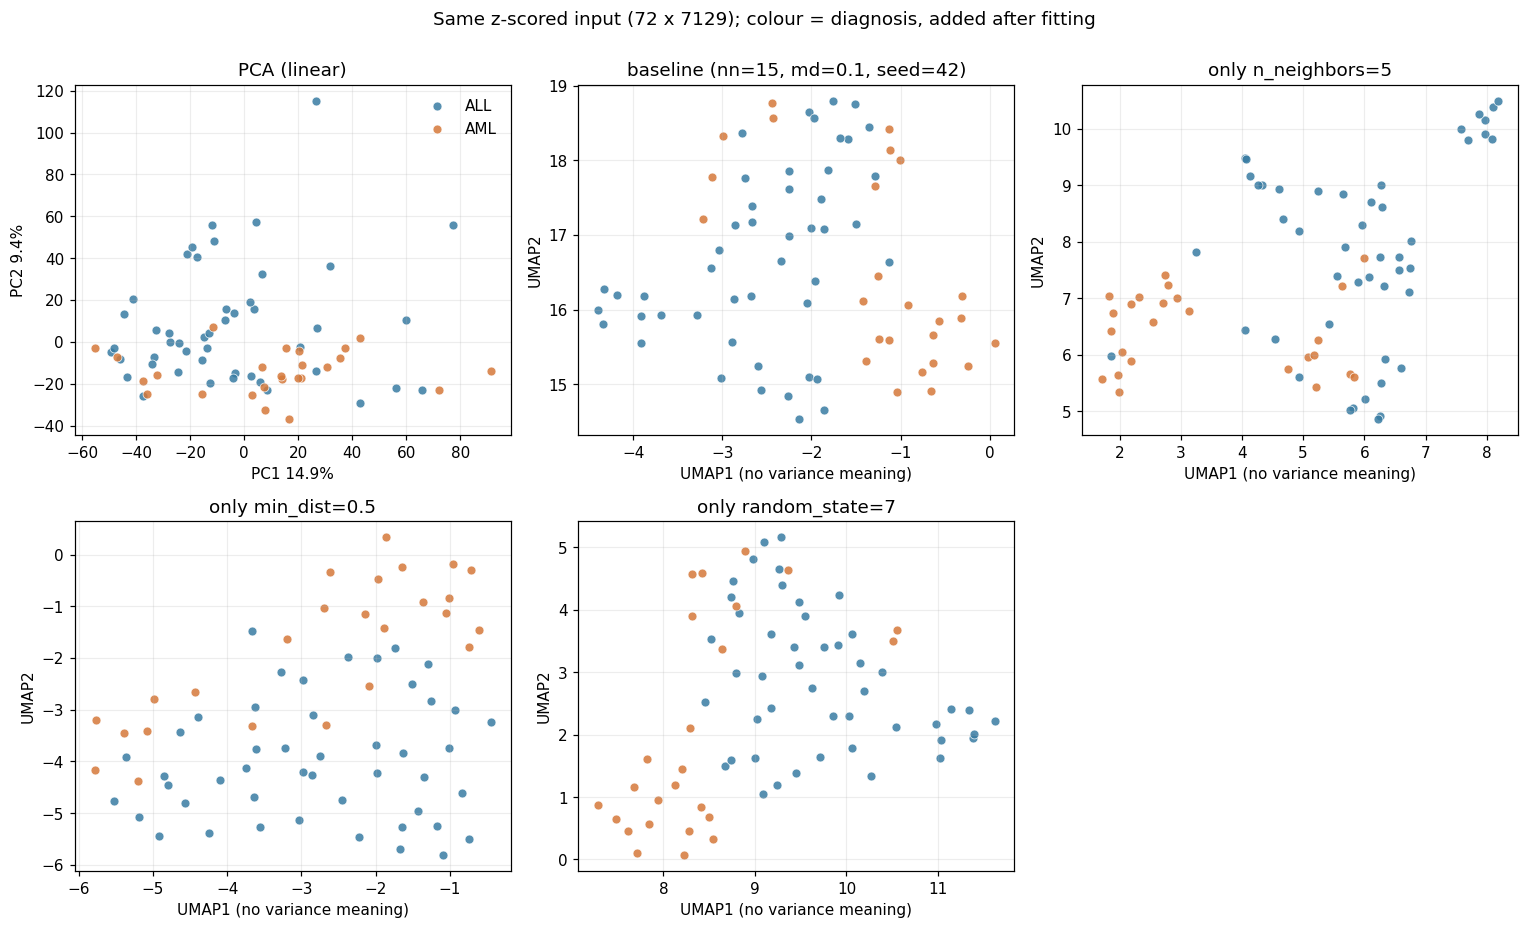

In [12]:
# 并排比较：PCA 与四种 UMAP
panels = [("PCA (linear)", S[:, :2], f"PC1 {evr[0]:.1%}", f"PC2 {evr[1]:.1%}")]
for name, E in emb.items():
    panels.append((name, E, "UMAP1 (no variance meaning)", "UMAP2"))

fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for ax, (title, Co, xl, yl) in zip(axes.ravel(), panels):
    for label in ["ALL", "AML"]:
        m = y == label
        ax.scatter(Co[m, 0], Co[m, 1], s=34, alpha=0.85, c=COLORS[label],
                   edgecolor="white", linewidth=0.5, label=label)
    ax.set(xlabel=xl, ylabel=yl, title=title)
    ax.grid(alpha=0.22)
axes.ravel()[5].axis("off")
axes.ravel()[0].legend(frameon=False, loc="best")
fig.suptitle("Same z-scored input (72 x 7129); colour = diagnosis, added after fitting", y=1.00)
plt.tight_layout()
plt.savefig(OUT / "fig-pca-vs-umap-variants.png", bbox_inches="tight")
plt.show()


In [13]:
# 哪些邻近关系稳定？用 10 近邻集合的 Jaccard 交集逐对比较
K = 10
def knn_sets(M):
    idx = NearestNeighbors(n_neighbors=K + 1).fit(M).kneighbors(M, return_distance=False)
    return [set(row[1:]) for row in idx]        # 去掉自己

spaces = {"original 7129-d space": Z, "PCA (2-d)": S[:, :2]}
spaces.update(emb)
sets = {name: knn_sets(M) for name, M in spaces.items()}

names = list(sets)
jac = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        jac.loc[a, b] = np.mean([len(sa & sb) / len(sa | sb) for sa, sb in zip(sets[a], sets[b])])

print("10 近邻集合的 Jaccard 一致度（1.0 = 完全相同）")
print(jac.round(3).to_string())
jac.to_csv(OUT / "task3-neighbor-jaccard.csv")

base = "baseline (nn=15, md=0.1, seed=42)"
print("\n基线 vs 改 seed=7     : %.3f" % jac.loc[base, "only random_state=7"])
print("基线 vs 改 nn=5        : %.3f" % jac.loc[base, "only n_neighbors=5"])
print("基线 vs 改 md=0.5      : %.3f" % jac.loc[base, "only min_dist=0.5"])
print("基线 vs 高维原空间近邻 : %.3f" % jac.loc[base, "original 7129-d space"])
print("PCA(2维) vs 高维原空间 : %.3f" % jac.loc["PCA (2-d)", "original 7129-d space"])


10 近邻集合的 Jaccard 一致度（1.0 = 完全相同）
                                   original 7129-d space  PCA (2-d)  baseline (nn=15, md=0.1, seed=42)  only n_neighbors=5  only min_dist=0.5  only random_state=7
original 7129-d space                              1.000      0.282                              0.344               0.309              0.309                0.334
PCA (2-d)                                          0.282      1.000                              0.372               0.345              0.383                0.365
baseline (nn=15, md=0.1, seed=42)                  0.344      0.372                              1.000               0.499              0.507                0.606
only n_neighbors=5                                 0.309      0.345                              0.499               1.000              0.468                0.483
only min_dist=0.5                                  0.309      0.383                              0.507               0.468              1.000           

In [14]:
# 用 kNN 图的连通分量把“岛数”量化，避免只靠肉眼数簇
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def n_islands(E, k):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E, return_distance=False)[:, 1:]
    rows = np.repeat(np.arange(len(E)), k)
    A = coo_matrix((np.ones(len(rows)), (rows, idx.ravel())), shape=(len(E), len(E)))
    ncomp, lab = connected_components(A, directed=False)
    sizes = sorted(np.bincount(lab), reverse=True)
    aml = sorted((int(np.sum(y[lab == i] == "AML")) for i in range(ncomp)), reverse=True)
    return ncomp, sizes, aml

print("每个点连到最近 k 个点，数连通分量（参数只有 k）：")
for k in (3, 5):
    print(f"  --- k = {k} ---")
    for name, E in emb.items():
        ncomp, sizes, aml = n_islands(E, k)
        print("  %-34s 分量数 %d  大小 %s  AML 数 %s" % (name, ncomp, sizes, aml))


每个点连到最近 k 个点，数连通分量（参数只有 k）：
  --- k = 3 ---
  baseline (nn=15, md=0.1, seed=42)  分量数 1  大小 [np.int64(72)]  AML 数 [25]
  only n_neighbors=5                 分量数 4  大小 [np.int64(27), np.int64(27), np.int64(10), np.int64(8)]  AML 数 [21, 2, 2, 0]
  only min_dist=0.5                  分量数 1  大小 [np.int64(72)]  AML 数 [25]
  only random_state=7                分量数 1  大小 [np.int64(72)]  AML 数 [25]
  --- k = 5 ---
  baseline (nn=15, md=0.1, seed=42)  分量数 1  大小 [np.int64(72)]  AML 数 [25]
  only n_neighbors=5                 分量数 2  大小 [np.int64(64), np.int64(8)]  AML 数 [25, 0]
  only min_dist=0.5                  分量数 1  大小 [np.int64(72)]  AML 数 [25]
  only random_state=7                分量数 1  大小 [np.int64(72)]  AML 数 [25]


In [15]:
# 保留坐标与样本编号的对应表，便于追踪同一个样本
coords = pd.DataFrame({
    "sample_id": df["sample_id"],
    "diagnosis": df["diagnosis"],
    "original_split": df["original_split"],
    "PC1": S[:, 0], "PC2": S[:, 1],
    "raw_PC1": S_raw[:, 0],
})
for name, E in emb.items():
    tag = TAGS[name]
    coords[f"UMAP_{tag}_1"] = E[:, 0]
    coords[f"UMAP_{tag}_2"] = E[:, 1]

coords.to_csv(OUT / "task3-coordinates.csv", index=False)
print("已保存坐标表:", OUT / "task3-coordinates.csv", "| 形状", coords.shape)
print(coords.head(3).round(4).to_string(index=False))
print("\n同一样本在不同设置下的位置（示例）：")
show = ["sample_id", "diagnosis", "PC1", "PC2"] + [c for c in coords.columns if c.startswith("UMAP_")][:2]
print(coords.loc[[0, 1, 35], show].round(3).to_string(index=False))


已保存坐标表: /Users/wenliangyu/Desktop/人工智能课程ppt资料作业/git-practice-classroom/.tmp/dimension-reduction/student-results/task3-coordinates.csv | 形状 (72, 14)
sample_id diagnosis original_split     PC1     PC2     raw_PC1  UMAP_nn15_md0.1_rs42_1  UMAP_nn15_md0.1_rs42_2  UMAP_nn5_1  UMAP_nn5_2  UMAP_md0.5_1  UMAP_md0.5_2  UMAP_rs7_1  UMAP_rs7_2
     G001       ALL          train 27.1052  6.4485 -12371.3427                 -2.5626                 14.9219      4.6000      8.9344       -1.2541       -2.8346      9.4482      1.3876
     G002       ALL          train  3.5074 15.8458 -37565.8661                 -2.8649                 16.1416      6.2836      8.6161       -1.6274       -3.8389      9.8544      2.2944
     G003       ALL          train 60.0064 10.3923 -19116.3669                 -2.6003                 15.2446      5.2481      8.8939       -0.9362       -3.0146      9.7103      1.6411

同一样本在不同设置下的位置（示例）：
sample_id diagnosis    PC1     PC2  UMAP_nn15_md0.1_rs42_1  UMAP_nn15_md0.1_rs42_2
 

In [16]:
# 客观核对“图上看分得开”是不是算法造成的：类间平均距离 / 类内平均距离
from scipy.spatial.distance import cdist

print("%-34s %10s %10s %10s %10s" % ("space", "within AML", "within ALL", "between", "between/within"))
for name, M in [("original 7129-d space", Z), ("PCA (2-d)", S[:, :2])] + list(emb.items()):
    D = cdist(M, M)
    np.fill_diagonal(D, np.nan)
    within_aml = np.nanmean(D[np.ix_(is_aml == 1, is_aml == 1)])
    within_all = np.nanmean(D[np.ix_(is_aml == 0, is_aml == 0)])
    between = np.nanmean(D[np.ix_(is_aml == 1, is_aml == 0)])
    print("%-34s %10.3f %10.3f %10.3f %10.3f"
          % (name[:34], within_aml, within_all, between, between / np.mean([within_aml, within_all])))

print("\n（描述性核对，不作预测评价）2 维坐标上留一法 1 近邻的 BA：")
for name, M in [("PCA (2-d)", S[:, :2])] + list(emb.items()):
    pred = NearestNeighbors(n_neighbors=2).fit(M).kneighbors(M, return_distance=False)[:, 1]
    print("   %-34s %.4f" % (name, balanced_accuracy_score(y, y[pred])))


space                              within AML within ALL    between between/within
original 7129-d space                 119.847    114.184    121.467      1.038
PCA (2-d)                              42.838     51.189     53.261      1.133
baseline (nn=15, md=0.1, seed=42)       1.920      1.877      2.335      1.230
only n_neighbors=5                      2.092      2.690      3.584      1.499
only min_dist=0.5                       2.697      2.360      3.280      1.297
only random_state=7                     2.230      1.786      2.579      1.284

（描述性核对，不作预测评价）2 维坐标上留一法 1 近邻的 BA：
   PCA (2-d)                          0.6430
   baseline (nn=15, md=0.1, seed=42)  0.8268
   only n_neighbors=5                 0.8255
   only min_dist=0.5                  0.8174
   only random_state=7                0.8055


### 任务 3.1 PCA 与 UMAP 比较表

| 比较项 | PCA | UMAP |
|---|---|---|
| 线性 / 非线性 | 线性投影（正交方向） | 非线性流形嵌入 |
| 优化或保留的主要信息 | 逐步最大化投影方差，全局结构优先 | 尽量保留 k 近邻图（局部邻域） |
| 坐标轴含义 | 可追踪：每一轴是 7129 个探针的确定权重组合 | 无固定含义，UMAP1/UMAP2 不是“基因轴”或“疾病轴” |
| 能否报告方差解释率 | 能，本次 PC1 14.92%、PC2 9.45% | 不能，没有与 PCA 等价的总方差口径 |
| 局部邻域与全局距离的解读 | 距离可比，但只覆盖前两轴 24.37% 的方差 | 局部近邻可参考；岛间距、面积、朝向、点密度都不能量化生物学差异 |
| 参数与随机性 | 确定性（本例 `svd_solver='full'`，无随机性） | 受 `n_neighbors`、`min_dist`、度量与随机种子共同影响 |
| 用于预测时如何避免泄露 | 在训练折内 `fit`，再 `transform` 验证折 | 同样必须在训练数据上 `fit`，并固定全部参数 |


### 任务 3.2 问题回答

**哪些邻近关系在不同设置下较稳定？** 以每个样本的 10 近邻集合计（Jaccard）：改种子（42→7）后与基线重合 **0.606**，改 `n_neighbors`（15→5）后重合 **0.499**，改 `min_dist`（0.1→0.5）后重合 **0.507**。也就是说，**大约一半的局部近邻关系是稳的，另一半随设置漂移**，其中随机种子的影响反而最小。与高维原空间的真实 10 近邻相比，基线 UMAP 只重合 **0.344**，PCA 二维只重合 **0.282**——二维图都丢掉了约三分之二的高维邻域关系。

**岛屿数量、岛屿间距离、方向和面积是否稳定？** 都不稳定，而且差异可以用“每个点连最近 k 个点、数连通分量”量化（参数只有 k）：

| 运行 | k=3 的分量数 | k=5 的分量数 | 分量大小 |
|---|---|---|---|
| 基线（nn=15, md=0.1, seed=42） | 1 | 1 | 72 |
| 只改 `n_neighbors=5` | **4** | **2** | 27 / 27 / 10 / 8（k=3）；64 / 8（k=5） |
| 只改 `min_dist=0.5` | 1 | 1 | 72 |
| 只改 `random_state=7` | 1 | 1 | 72 |

也就是说，**基线在两种定义下都只有一个连通团块**；只有把 `n_neighbors` 降到 5，才裂出多个岛——k=5 时那个 8 点的孤立岛**全部是 ALL**。同一份数据、同一套预处理，岛数在 1 到 4 之间随一个参数跳动，所以不能数“图上有几个岛”就断言有几个亚型。

方向和面积同样不稳定：四次运行的坐标范围互不相同（基线 x∈[−4.39, 0.06]、y∈[14.54, 18.80]；`random_state=7` 为 x∈[7.29, 11.62]、y∈[0.07, 5.17]），整体平移、旋转甚至翻转，说明**方向和绝对位置没有意义**，岛间距也不能当作生物学距离。

**为什么 UMAP 常用于单细胞或复杂表型展示？** 它擅长把高维中“谁和谁是近邻”的局部关系压到二维里，对非线性、连续谱系（如分化轨迹）比线性 PCA 更直观，且计算上可扩展到大量细胞，所以适合**探索性展示**、提出关于亚群的假设。

**图上分离能否证明疾病机制、真实亚型数量或新患者预测性能？** 都不能。类间/类内平均距离比在原始 7129 维是 **1.038**、二维 PCA 是 **1.133**、UMAP 基线是 **1.230**——分离度是**算法把类内压紧之后**才显得明显的，是可视化结果而不是数据性质。二维坐标上的 1 近邻 BA（PCA 0.6430、UMAP 0.8268 等）只是描述性核对，不是对新患者的预测性能；真正的预测必须在独立的、未参与任何选择的样本上评价。降维图只能提出假设，不能确认机制或亚型数量。

**本数据缺少批次字段，能否宣称已经排除批次影响？** 不能。数据没有采集批次、芯片批次或处理时间字段，任何分组差异都可能来自批次；既然无法观测批次，就无法排除它，也就不存在“已经排除”的证据。


### 任务 3.3 三条“图能支持什么 / 不能支持什么”

1. **能支持**：在这批 72 个样本、这套预处理与参数下，AML 与 ALL 的局部邻域在一定程度上分开（类间/类内平均距离比 1.23），可以作为“两类样本表达谱存在差异”的**探索性线索**。
2. **不能支持**：不能由岛屿数量推断真实亚型数，也不能把岛间距、面积或朝向当作生物学差异的量——改种子或改 `n_neighbors` 后，10 近邻只保留 50%–61%，坐标范围整体改变。
3. **不能支持**：不能由二维图宣称对新患者有预测能力，更不能宣称机制。预测能力需要在折内拟合的 Pipeline 加独立测试集上评价；机制需要独立的生物学实验。


## 任务 4：给研究团队写一份结论

**主张。** 不同意“二维图上分得开，就证明发现了疾病机制，并且可以预测新患者”——二维图给出的是关于这 72 个样本的一个可探索的假设，不是机制证据，也不是泛化证据。

**证据。** PCA 的 PC1 与 PC2 合计只解释总方差的 **24.37%**，PC1 单独 14.92%；PC1 上权重最大的探针 `X92518_s_at`（+0.0288）只是加权和里的一项，把前 5 个探针单独相加，只复现样本 G001 的 PC1 得分的 **0.5%**；而且 PC1 并不是最会分的方向——沿 PC1 单阈值分类最优 BA 仅 0.7123，沿类别均值差方向可达 0.9281。UMAP 侧，改随机种子（42→7）后 10 近邻集合只保留 **0.606** 的 Jaccard 一致度，改 `n_neighbors` 到 5 只保留 **0.499**，且四次运行的坐标范围完全不同。

**推理。** 降维图展示的是“算法在二维里保住了什么”，不是“数据里有什么因果结构”。轴的方向、簇的位置、面积和间距由参数与随机性共同决定，PCA 的分离还受“方差最大 ≠ 判别力最强”的限制。因此图上的分离只能升级为关于样本结构的假设，不能反推生物学机制，也不等价于对未见样本的预测表现。

**边界。** 以上结论全部限定在 Golub 数据 72 个样本、一次测量、逐列 z-score、欧氏距离、无批次字段、无外部队列的条件下；`n_neighbors`、`min_dist`、种子只做了单因素对照，没有做参数搜索，也没有做多批次重复。**若要把图上的模式升级为生物医学结论，我提出一项额外验证：**在一个含批次信息的独立队列上，固定同一套预处理与模型（全部折内拟合），检验（a）分组结构能否重现、（b）在一个从未参与任何分析与选参的外部样本集上，预测表现能否复现。

## 退出卡

- 主张：二维分离只是关于这批样本的假设，不证明机制，也不证明对新患者的预测能力。
- 证据（PCA）：PC1+PC2 只解释 24.37% 总方差；PC1 单阈值最优 BA 0.7123，低于类别均值差方向的 0.9281。
- 证据（UMAP 对照）：改种子后 10 近邻仅保留 0.606、改 `n_neighbors=5` 仅保留 0.499，坐标范围整体改变。
- 推理：图保住的只是局部邻域，且部分由参数与随机性决定。
- 边界：72 样本、单次测量、无批次字段、无外部队列。
- 下一步验证：独立队列 + 折内拟合的 Pipeline，检验分组重现与外部预测表现。


## 课后三道作业（用自己的话）

**1. PCA 第一主成分代表什么？结合本次解释率和一个探针权重回答。**

第一主成分是这样一个方向：把所有样本的 7129 个探针值先各自标准化，再按这个方向的权重加权求和，得到的那个分数（得分）在样本间变化最大——它是“投影后方差最大”的一维方向，不是最有生物学意义的方向。本次 PC1 解释总方差的 **14.92%**，PC2 再解释 9.45%，两者合计 24.37%，也就是说前两轴合起来还不到四分之一。在这个方向上权重绝对值最大的是探针 `X92518_s_at`，权重 **+0.0288**；符号为正表示它与 PC1 得分同向变化，但符号取决于 SVD 的任意朝向，整体翻号不改变结果。要强调的是，权重 0.0288 只是 7129 项加权和中的一项，把权重前 5 的探针单独加起来也只复现了样本 G001 得分的 0.5%，所以不能把“PC1 上权重最大”读成“这个探针最重要”。

**2. 为什么 PCA 前通常需要考虑标准化？结合原尺度对照说明它的作用与代价。**

因为 PCA 找的是方差最大的方向，而原尺度下各列的方差差了几个数量级：本数据各列方差最小 7.03×10²、中位数 3.39×10⁴、最大 2.49×10⁸，最大是最小的约 **35 万倍**。不标准化时，原尺度 PC1 几乎被方差最大的那几列牵着走——前 5 个高权重探针是 `M25079_s_at`(+0.352)、`hum_alu_at`(+0.314) 等，与标准化后的前 5 个**零重叠**，原尺度 PC1 也解释到 17.43%，看起来“更好”但只是同一批大方差列的重复。标准化把每列换算成自身标准差单位，让各列权重可比，主成分反映的是**相关结构**而不是量纲。代价是：低变异列被放大到和真实信号列同样的权重，如果低变异主要来自测量噪声，噪声也会被一起放大；所以本分析同时保留了原尺度对照，而不是只比较谁的解释率高。

**3. UMAP 图能说明什么，不能说明什么？结合一次参数或种子对照说明。**

UMAP 图能说明的是：在这套参数下，哪些样本被放进了同一个局部邻域，从而提示可能存在的分组或连续梯度——这是提出假设用的。它不能说明亚型数量、机制，也不能说明对新患者的预测能力，因为嵌入是“尽量保住近邻图”的优化结果，轴无含义、岛间距无标尺、且随参数和随机性变化。证据：同一份标准化矩阵，只把随机种子从 42 改成 7，10 近邻集合的 Jaccard 一致度只有 **0.606**；只把 `n_neighbors` 从 15 改成 5，只有 **0.499**；四次运行的坐标范围互不相同。也就是说，大约一半的局部关系随设置漂移，所以不能挑一张最好看的图当结论。
